# XGBoost Regression

In the previous notebook, we studied Gradient Boosting Regression.

Our tuned Gradient Boosting model achieved a test R² score of approximately 0.842 on the California Housing dataset.

Gradient Boosting builds decision trees sequentially. Each new tree attempts to improve the predictions made by the existing ensemble.

XGBoost, short for Extreme Gradient Boosting, is an optimized and regularized implementation of gradient-boosted decision trees.

The basic idea is similar to Gradient Boosting:

\[
F_m(x)=F_{m-1}(x)+ ηh_m(x)
\]

where each new tree improves the existing ensemble.

However, XGBoost introduces additional techniques for controlling model complexity and improving optimization and computational efficiency.

In this notebook, we will:

1. Understand the intuition behind XGBoost.
2. Understand how XGBoost differs from standard Gradient Boosting.
3. Train a basic XGBoost regression model.
4. Evaluate its performance.
5. Study important hyperparameters.
6. Tune the model using cross-validation.
7. Examine feature importance.
8. Compare XGBoost with our previous regression models.

The goal is to understand both the algorithm and its practical use in a real machine learning project.

In [1]:
import xgboost
print(xgboost.__version__)

3.4.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (16512, 8)
Test set: (4128, 8)


In [4]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    random_state = 42
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [5]:
y_pred_xgb = xgb_model.predict(X_test)

In [6]:
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_mse = mean_squared_error(y_test, y_pred_xgb)

xgb_rmse = np.sqrt(xgb_mse)

xgb_r2 = r2_score(y_test, y_pred_xgb)

print("MAE:", xgb_mae)
print("MSE:", xgb_mse)
print("RMSE:", xgb_rmse)
print("R²:", xgb_r2)

MAE: 0.31074241395526386
MSE: 0.21404356860001178
RMSE: 0.46264842872316314
R²: 0.8366589575055071


In [7]:
depth_results = []

for depth in [2, 3, 4, 5, 6, 7, 8]:

    model = XGBRegressor(
        n_estimators = 300,
        learning_rate = 0.1,
        max_depth = depth,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    depth_results.append(
        [depth, r2, rmse]
    )

depth_df = pd.DataFrame(

    depth_results,
    columns=["Max Depth", "R²", "RMSE"]
)

depth_df

,Max Depth,R²,RMSE
0,2,0.785885,0.529696
1,3,0.815861,0.491220
2,4,0.831683,0.469642
3,5,0.840698,0.456893
4,6,0.845597,0.449813
5,7,0.842015,0.455000
6,8,0.843326,0.453108


## Effect of Tree Depth

The `max_depth` parameter controls the maximum depth of each decision tree in the XGBoost ensemble.

Shallow trees produce relatively simple corrections, while deeper trees can capture more complex relationships.

In our experiment, increasing `max_depth` from 2 to 6 steadily improved test performance. This suggests that the shallower trees were not sufficiently expressive for the California Housing dataset.

However, increasing the depth further to 8 slightly reduced performance. This suggests that increasing tree complexity indefinitely does not necessarily improve generalization and may begin to introduce overfitting.

Among the tested values, `max_depth=6` produced the strongest test performance:

- R² = 0.8456
- RMSE = 0.4498

We will not treat this test-set result as the final hyperparameter selection. The final configuration will be selected using cross-validation.

In [8]:
tree_results = []

for n_trees in [50, 100, 200, 300, 400, 500]:

    model = XGBRegressor(
        n_estimators = n_trees,
        learning_rate = 0.1,
        max_depth = 6,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    tree_results.append(
        [n_trees, r2, rmse]
    )

tree_df = pd.DataFrame(

    tree_results,
    columns=["N Estimators", "R²", "RMSE"]
)

tree_df

,N Estimators,R²,RMSE
0,50,0.806343,0.503755
1,100,0.828652,0.473853
2,200,0.841017,0.456435
3,300,0.845597,0.449813
4,400,0.847862,0.446501
5,500,0.848804,0.445116


## Effect of Number of Estimators

The `n_estimators` parameter controls the number of boosting trees in the XGBoost ensemble.

We kept `max_depth=6` and `learning_rate=0.1` fixed and varied the number of trees.

The results show that increasing the number of trees generally improves performance:

- 50 trees → R² = 0.8063
- 100 trees → R² = 0.8287
- 200 trees → R² = 0.8410
- 300 trees → R² = 0.8456
- 400 trees → R² = 0.8479
- 500 trees → R² = 0.8488

However, the improvement becomes progressively smaller as more trees are added.

For example, increasing the number of trees from 50 to 100 produces a much larger improvement than increasing it from 400 to 500.

This demonstrates diminishing returns: adding more boosting stages can continue improving the model, but each additional group of trees contributes less than the previous one.

Among the tested values, 500 trees produced the strongest test performance. However, we will not use the test set to make the final hyperparameter selection. The final configuration will be selected using cross-validation.

In [9]:
learning_results = []

for lr in [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5]:

    model = XGBRegressor(
        n_estimators = 500,
        learning_rate = lr,
        max_depth = 6,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    learning_results.append(
        [lr, r2, rmse]
    )

learning_df = pd.DataFrame(

    learning_results,
    columns=["Learning Rate", "R²", "RMSE"]
)

learning_df

,Learning Rate,R²,RMSE
0,0.01,0.806799,0.503162
1,0.03,0.836280,0.463185
2,0.05,0.842307,0.454579
3,0.10,0.848804,0.445116
4,0.20,0.841690,0.455468
5,0.30,0.839478,0.458639
6,0.50,0.811998,0.496347


## Effect of Learning Rate

The `learning_rate` parameter controls how strongly each new tree contributes to the existing ensemble.

XGBoost updates the prediction approximately as:

F_m(x) = F_{m-1}(x) + η h_m(x)

where `η` is the learning rate.

A smaller learning rate means that each tree makes a smaller correction. A larger learning rate allows each tree to make a larger correction.

In our experiment, the learning rate was varied while keeping `n_estimators=500` and `max_depth=6` fixed.

The results showed that:

- Very small learning rates required more boosting stages to make sufficient progress.
- Moderate learning rates produced stronger performance.
- Very large learning rates reduced performance, suggesting that the updates were becoming too aggressive.

The best result among the tested values was obtained with:

- Learning rate = 0.10
- R² = 0.8488
- RMSE = 0.4451

This demonstrates an important relationship between learning rate and the number of estimators. A smaller learning rate can require more trees, while a larger learning rate can reach its learning capacity with fewer trees.

We will use cross-validation later to select the final combination rather than selecting hyperparameters directly from the test set.

In [10]:
child_results = []

for weight in [1, 3, 5, 10, 20]:

    model = XGBRegressor(
        n_estimators = 500,
        learning_rate = 0.1,
        max_depth = 6,
        min_child_weight = weight,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    child_results.append(
        [weight, r2, rmse]
    )

child_df = pd.DataFrame(

    child_results,
    columns=["Min Child Weight", "R²", "RMSE"]
)

child_df

,Min Child Weight,R²,RMSE
0,1,0.848804,0.445116
1,3,0.844735,0.451065
2,5,0.846902,0.447908
3,10,0.849549,0.444018
4,20,0.849575,0.443980


## Effect of Minimum Child Weight

The `min_child_weight` parameter controls how conservative XGBoost is when creating new child nodes.

A larger value requires a child node to contain more training-instance weight before a split is considered useful.

Conceptually:

- Lower values allow splits more easily and can produce more complex trees.
- Higher values make the tree more conservative and can help prevent unnecessary splits.

In our experiment, we kept:

- `n_estimators = 500`
- `learning_rate = 0.1`
- `max_depth = 6`

and varied `min_child_weight`.

The results were:

- `1` → R² = 0.8488
- `3` → R² = 0.8447
- `5` → R² = 0.8469
- `10` → R² = 0.8495
- `20` → R² = 0.8496

Increasing `min_child_weight` did not produce a simple monotonic change in performance. The best result among the tested values occurred at `20`, but the improvement over `1` was very small.

This suggests that `min_child_weight` has a relatively modest effect on this dataset within the tested range.

We will allow cross-validation to determine its final value rather than selecting it from the test-set results.

In [11]:
subsample_results = []

for fraction in [0.5, 0.7, 0.8, 0.9, 1.0]:

    model = XGBRegressor(
        n_estimators = 500,
        learning_rate = 0.1,
        max_depth = 6,
        min_child_weight = 10,
        subsample=fraction,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    subsample_results.append(
        [fraction, r2, rmse]
    )

subsample_df = pd.DataFrame(

    subsample_results,
    columns=["Subsample", "R²", "RMSE"]
)

subsample_df

,Subsample,R²,RMSE
0,0.5,0.844483,0.451432
1,0.7,0.849131,0.444635
2,0.8,0.850231,0.443010
3,0.9,0.850735,0.442265
4,1.0,0.849549,0.444018


## Effect of Subsample

The `subsample` parameter controls the fraction of training observations used by each boosting stage.

For example, with `subsample=0.8`, each tree is trained using approximately 80% of the available training observations.

Using less than 100% of the training data introduces randomness into the boosting process. This can reduce the correlation between trees and may improve generalization.

In our experiment, we kept:

- `n_estimators = 500`
- `learning_rate = 0.1`
- `max_depth = 6`
- `min_child_weight = 10`

and varied `subsample`.

The results were:

- `0.5` → R² = 0.8445
- `0.7` → R² = 0.8491
- `0.8` → R² = 0.8502
- `0.9` → R² = 0.8507
- `1.0` → R² = 0.8495

The strongest result among the tested values occurred at `subsample=0.9`.

However, the difference between 0.9 and 1.0 was very small. This suggests that the exact subsampling fraction has a relatively modest effect within this range.

A very low subsample value such as 0.5 performed worse, likely because each tree had access to substantially less training information.

As with the previous experiments, we will use cross-validation to select the final hyperparameter configuration rather than relying on the test-set results.

In [12]:
feature_results = []

for feature in [0.5, 0.7, 0.8, 0.9, 1.0]:

    model = XGBRegressor(
        n_estimators = 500,
        learning_rate = 0.1,
        max_depth = 6,
        min_child_weight = 10,
        subsample=0.9,
        colsample_bytree=feature,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    feature_results.append(
        [feature, r2, rmse]
    )

feature_df = pd.DataFrame(

    feature_results,
    columns=["feature", "R²", "RMSE"]
)

feature_df

,feature,R²,RMSE
0,0.5,0.852560,0.439553
1,0.7,0.853004,0.438890
2,0.8,0.850200,0.443057
3,0.9,0.851212,0.441558
4,1.0,0.850735,0.442265


## Effect of Feature Subsampling

The `colsample_bytree` parameter controls the fraction of features available to each tree.

Our dataset contains eight input features. A value of `1.0` allows each tree to consider all features, while smaller values introduce feature subsampling.

This provides another source of randomness in the XGBoost ensemble.

In this experiment, we kept:

- `n_estimators = 500`
- `learning_rate = 0.1`
- `max_depth = 6`
- `min_child_weight = 10`
- `subsample = 0.9`

and varied `colsample_bytree`.

The results were:

- `0.5` → R² = 0.8526
- `0.7` → R² = 0.8530
- `0.8` → R² = 0.8502
- `0.9` → R² = 0.8512
- `1.0` → R² = 0.8507

The strongest result among the tested values occurred at `colsample_bytree=0.7`.

Feature subsampling can help by making the individual trees less similar to one another. However, using too small a fraction can also prevent a tree from considering useful features.

The differences in this experiment were relatively small, so the final value will be selected using cross-validation.

In [13]:
alpha_results = []

for alpha in [0, 0.01, 0.05, 0.1, 0.5, 1, 5, 6, 7, 10]:

    model = XGBRegressor(
        n_estimators = 500,
        learning_rate = 0.1,
        max_depth = 6,
        min_child_weight = 10,
        subsample=0.9,
        colsample_bytree=0.7,
        reg_alpha=alpha,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    alpha_results.append(
        [alpha, r2, rmse]
    )

alpha_df = pd.DataFrame(

    alpha_results,
    columns=["Reg Alpha", "R²", "RMSE"]
)

alpha_df

,Reg Alpha,R²,RMSE
0,0.00,0.853004,0.438890
1,0.01,0.855684,0.434872
2,0.05,0.853835,0.437648
3,0.10,0.852578,0.439526
4,0.50,0.854429,0.436759
5,1.00,0.856038,0.434337
6,5.00,0.856957,0.432949
7,6.00,0.856350,0.433866
8,7.00,0.854270,0.436996
9,10.00,0.852562,0.439550


## Effect of L1 Regularization

XGBoost supports explicit regularization to control model complexity.

The `reg_alpha` parameter controls the strength of L1 regularization.

Conceptually, the XGBoost objective contains two components:

Objective = Training Loss + Complexity Penalty

L1 regularization adds a penalty related to the magnitude of the model's leaf weights.

In this experiment, we kept the previously studied parameters fixed and varied `reg_alpha`.

The results were:

- `0` → R² = 0.8530
- `0.01` → R² = 0.8557
- `0.05` → R² = 0.8538
- `0.1` → R² = 0.8526
- `0.5` → R² = 0.8544
- `1` → R² = 0.8560
- `5` → R² = 0.8570
- `6` → R² = 0.8564
- `7` → R² = 0.8543
- `10` → R² = 0.8526

The strongest result among the tested values occurred at `reg_alpha=5`.

The relationship is not monotonic. Increasing regularization initially improved performance, but larger values eventually reduced performance.

This illustrates the trade-off involved in regularization. Too little regularization may allow unnecessary complexity, while too much regularization can constrain the model excessively.

The final value will be selected using cross-validation rather than the test-set result alone.

In [14]:
lambda_results = []

for reg_lambda in [0, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 6, 7, 10, 20]:

    model = XGBRegressor(
        n_estimators = 500,
        learning_rate = 0.1,
        max_depth = 6,
        min_child_weight = 10,
        subsample=0.9,
        colsample_bytree=0.7,
        reg_alpha=5,
        reg_lambda=reg_lambda,
        random_state = 42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    lambda_results.append(
        [reg_lambda, r2, rmse]
    )

lambda_df = pd.DataFrame(

    lambda_results,
    columns=["Reg Lambda", "R²", "RMSE"]
)

lambda_df

,Reg Lambda,R²,RMSE
0,0.00,0.855501,0.435147
1,0.01,0.855724,0.434811
2,0.05,0.855221,0.435569
3,0.10,0.855091,0.435764
4,0.50,0.856439,0.433732
5,1.00,0.856957,0.432949
6,2.00,0.856378,0.433824
7,5.00,0.855113,0.435731
8,6.00,0.855835,0.434644
9,7.00,0.856217,0.434067


## Effect of L2 Regularization

The `reg_lambda` parameter controls the strength of L2 regularization in XGBoost.

L2 regularization adds a penalty related to the squared magnitude of the model's leaf weights.

Conceptually:

L2 penalty ∝ λ Σ w_j²

The purpose of this penalty is to discourage excessively large model corrections and help control model complexity.

In this experiment, we kept `reg_alpha=5` and varied `reg_lambda`.

The results showed relatively small changes in performance.

The strongest result among the tested values occurred at:

- `reg_lambda = 1`
- R² = 0.8570
- RMSE = 0.4329

Increasing `reg_lambda` beyond this value did not produce a consistent improvement.

This suggests that the effect of L2 regularization is relatively modest for the current model configuration.

It is also important to remember that the best values of `reg_alpha` and `reg_lambda` cannot be determined independently with certainty. Their interaction with the other XGBoost hyperparameters should be evaluated using cross-validation.

In [15]:
param_grid_xgb = {
    "n_estimators": [400, 500],
    "learning_rate": [0.05, 0.1],
    "max_depth": [6, 8],
    "min_child_weight": [10, 20],
    "subsample": [0.9, 1.0],
    "colsample_bytree": [0.5, 0.7],
    "reg_alpha": [1, 5],
    "reg_lambda": [0.5, 1]
}

from sklearn.model_selection import GridSearchCV

xgb = XGBRegressor(
    random_state = 42,
    n_jobs=-1
)

grid_search_xbr = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

In [16]:
grid_search_xbr.fit(X_train, y_train)

Fitting 5 folds for each of 256 candidates, totalling 1280 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.5, 0.7], 'learning_rate': [0.05, 0.1], 'max_depth': [6, 8], 'min_child_weight': [10, 20], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_

In [17]:
grid_search_xbr.best_params_

{'colsample_bytree': 0.7,
 'learning_rate': 0.05,
 'max_depth': 8,
 'min_child_weight': 20,
 'n_estimators': 500,
 'reg_alpha': 5,
 'reg_lambda': 1,
 'subsample': 1.0}

In [18]:
grid_search_xbr.best_score_

np.float64(0.849870156503688)

In [19]:
best_xgb = grid_search_xbr.best_estimator_

In [20]:
y_pred_best_xgb = best_xgb.predict(X_test)

gbr_mae = mean_absolute_error(y_test, y_pred_best_xgb)
gbr_mse = mean_squared_error(y_test, y_pred_best_xgb)
gbr_rmse = np.sqrt(gbr_mse)
gbr_r2 = r2_score(y_test, y_pred_best_xgb)

print("MAE:", gbr_mae)
print("MSE:", gbr_mse)
print("RMSE:", gbr_rmse)
print("R²:", gbr_r2)

MAE: 0.2833017456371401
MSE: 0.1885604815465787
RMSE: 0.43423551391679
R²: 0.8561056245205956


## Feature Importance

After tuning our XGBoost model, we will examine which input features contribute most to its predictions.

XGBoost provides feature importance scores based on how features are used in the trained trees. These scores help us understand which features the model relies on most when making predictions.

We will extract the importance scores, sort them in descending order, and visualize them.

Feature importance has some limitations:

- It describes the model's use of features, not necessarily their real-world causal influence.
- A high importance score does not indicate whether a feature increases or decreases predicted house prices.
- Correlated features can share or influence one another's importance scores.

This analysis helps us interpret the trained model, but it does not establish causal relationships between housing features and prices.

In [21]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,MedInc,0.455755
7,Longitude,0.125364
6,Latitude,0.118296
5,AveOccup,0.112104
2,AveRooms,0.101844
1,HouseAge,0.054086
3,AveBedrms,0.019704
4,Population,0.012848


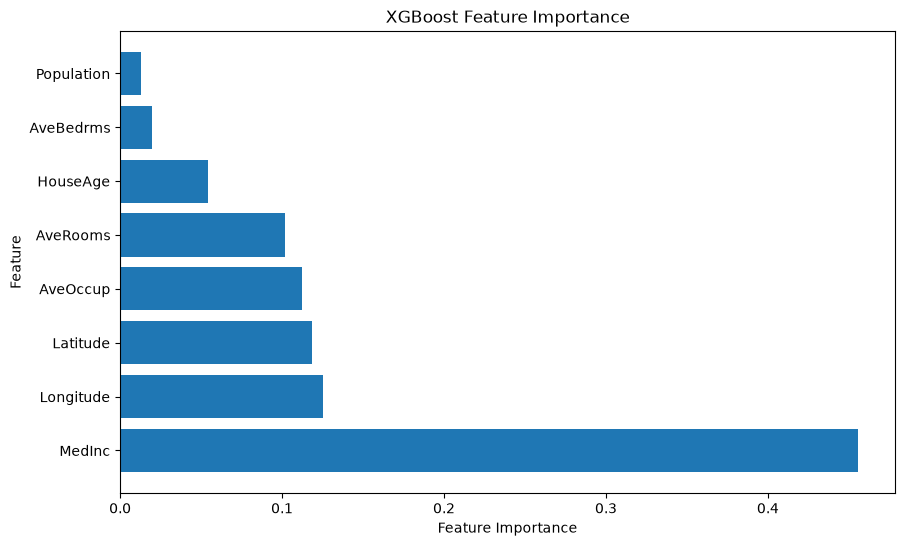

In [22]:
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.gca().invert_yaxis
plt.tight_layout
plt.show()

### Feature Importance: Key Findings

The feature-importance analysis shows that `MedInc` is the dominant feature in our tuned XGBoost model. This agrees with our earlier exploratory analysis, where median income had the strongest Pearson correlation with the target.

`Longitude` and `Latitude` also have substantial importance, highlighting the predictive value of geographic information. `AveOccup` and `AveRooms` contribute meaningfully as well.

An interesting observation is that `AveOccup` had a Pearson correlation close to zero, yet it receives considerable importance in XGBoost. This demonstrates that linear correlation alone cannot capture every useful nonlinear relationship in the data.

Feature importance describes how the trained model uses its input features. It does not establish causal relationships, indicate the direction of a feature's effect, or guarantee that the same importance ranking will hold for every model.

In [23]:
y_pred_xgb = best_xgb.predict(X_test)

error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_xgb
})

error_analysis["Residual"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["Absolute Error"] = (
    error_analysis["Residual"].abs()
)

error_analysis.head(10)

,Actual,Predicted,Residual,Absolute Error
20046,0.47700,0.523079,-0.046079,0.046079
3024,0.45800,0.821291,-0.363291,0.363291
15663,5.00001,5.122857,-0.122847,0.122847
20484,2.18600,2.445718,-0.259718,0.259718
9814,2.78000,2.400529,0.379471,0.379471
13311,1.58700,1.492997,0.094003,0.094003
7113,1.98200,2.289072,-0.307072,0.307072
7668,1.57500,1.575599,-0.000599,0.000599
18246,3.40000,3.120695,0.279305,0.279305
5723,4.46600,4.974072,-0.508072,0.508072


## Initial Prediction Error Analysis

We calculated residuals and absolute errors for the test predictions.

Residual = Actual − Predicted

A negative residual indicates overprediction, while a positive residual indicates underprediction. The absolute error measures the magnitude of the prediction error without considering its direction.

The first ten predictions show that the model can produce very accurate estimates for some observations, while making substantial errors for others.

For example, one prediction differs from the actual value by only about $60, whereas another differs by approximately $50,807.

We also observed a prediction above the dataset's target cap of approximately $500,000. This illustrates that XGBoost regression does not automatically constrain predictions to the observed target range.

These examples provide an initial view of model errors, but the first ten observations are not sufficient to determine the model's overall error patterns. We will next examine the largest errors across the entire test set.

In [24]:
largest_errors = error_analysis.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

largest_errors

,Actual,Predicted,Residual,Absolute Error
12389,5.00001,1.818973,3.181037,3.181037
19542,4.50000,1.467051,3.032949,3.032949
6688,5.00001,2.018894,2.981116,2.981116
5887,0.17500,3.117774,-2.942774,2.942774
12069,5.00001,2.380106,2.619904,2.619904
20349,1.25000,3.788656,-2.538656,2.538656
459,5.00001,2.503132,2.496878,2.496878
20325,5.00001,2.546068,2.453942,2.453942
15624,5.00001,2.684994,2.315016,2.315016
10574,5.00001,2.857446,2.142564,2.142564


### Analysis of the Largest Prediction Errors

We sorted the test predictions by absolute error to identify the observations for which the model performed worst.

Several patterns emerged:

1. Many of the largest errors occurred for observations with a target value of `5.00001`, corresponding to the dataset's upper price cap. The model substantially underpredicted these observations.
2. Some unusually low-value observations were substantially overpredicted.
3. The largest errors demonstrate that strong overall metrics do not guarantee accurate predictions for every individual observation.

The target cap is an important limitation of the California Housing dataset. For observations at the cap, the recorded target does not reveal the actual value beyond the upper limit.

These errors may reflect unusual feature combinations, missing explanatory information, or limitations of the available data. We will inspect the corresponding input features before drawing further conclusions.

In [25]:
worst_indices = largest_errors.index

worst_houses = X_test.loc[worst_indices].copy()

worst_houses["Actual"] = y_test.loc[worst_indices]
worst_houses["Predicted"] = best_xgb.predict(X_test.loc[worst_indices])

worst_houses["Absolute Error"] = (
    worst_houses["Actual"] - worst_houses["Predicted"]
).abs()

worst_houses.sort_values(
    by="Absolute Error",
    ascending=False
)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Absolute Error
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,1.818973,3.181037
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,1.467051,3.032949
6688,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,2.018894,2.981116
5887,2.3667,39.0,3.572464,1.217391,259.0,1.876812,34.15,-118.33,0.17500,3.117774,2.942774
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,2.380106,2.619904
20349,7.3004,32.0,5.724138,0.758621,63.0,2.172414,34.17,-119.08,1.25000,3.788656,2.538656
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,2.503132,2.496878
20325,4.5833,21.0,7.278431,1.082353,863.0,3.384314,34.28,-119.04,5.00001,2.546068,2.453942
15624,2.5875,52.0,3.287449,1.020243,629.0,2.546559,37.80,-122.41,5.00001,2.684994,2.315016
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,2.857446,2.142564


### Investigating the Largest Prediction Errors

We examined the input features of the ten test observations with the largest absolute prediction errors.

Several observations had actual target values of `5.00001`, corresponding to the dataset's upper target cap. The model substantially underpredicted these observations, demonstrating a limitation of learning from capped target values.

The remaining large errors included both overpredictions and underpredictions. Median income alone could not explain these cases, suggesting that other features and combinations of features also influence prediction quality.

The observations came from different geographic areas and contained varied housing characteristics. However, this analysis does not establish a single cause for the errors.

We did not remove these observations from the test set. Doing so after examining model errors would bias our evaluation. Instead, we retain them as evidence of the model's limitations on difficult cases.

Overall, the analysis demonstrates that strong aggregate evaluation metrics do not guarantee accurate predictions for every individual observation.

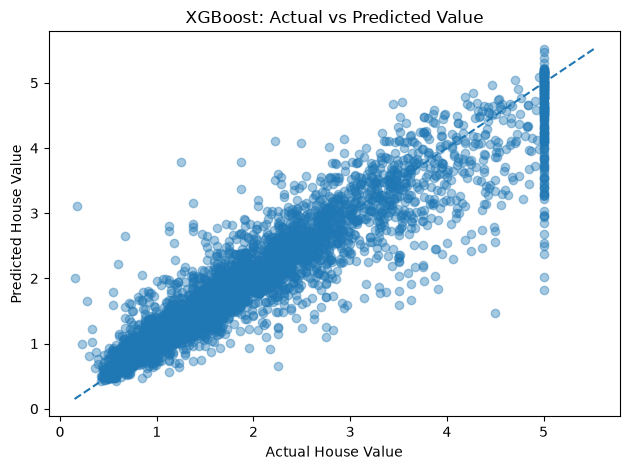

In [26]:
plt.scatter(y_test, y_pred_xgb, alpha=0.4)

min_value = min(y_test.min(), y_pred_xgb.min())
max_value = max(y_test.max(), y_pred_xgb.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("XGBoost: Actual vs Predicted Value")

plt.tight_layout()
plt.show()

### Actual vs. Predicted Values

We plotted the actual test targets against the predictions from our tuned XGBoost model. The dashed diagonal represents perfect predictions, where the predicted value equals the actual value.

Most observations cluster around the diagonal, indicating that the model captures the overall relationship between the input features and house values.

However, the spread of points increases at higher actual values, suggesting that prediction errors tend to become larger for expensive houses. Several observations also lie far from the diagonal, representing substantial individual prediction errors.

A distinct vertical band appears near the target value of 5.0. This occurs because the California Housing target is capped at approximately $500,000, causing many observations to share the same recorded target while receiving different model predictions.

Overall, the plot supports the model's strong aggregate performance while highlighting limitations at the high-value end of the target distribution and for individual outlier observations.

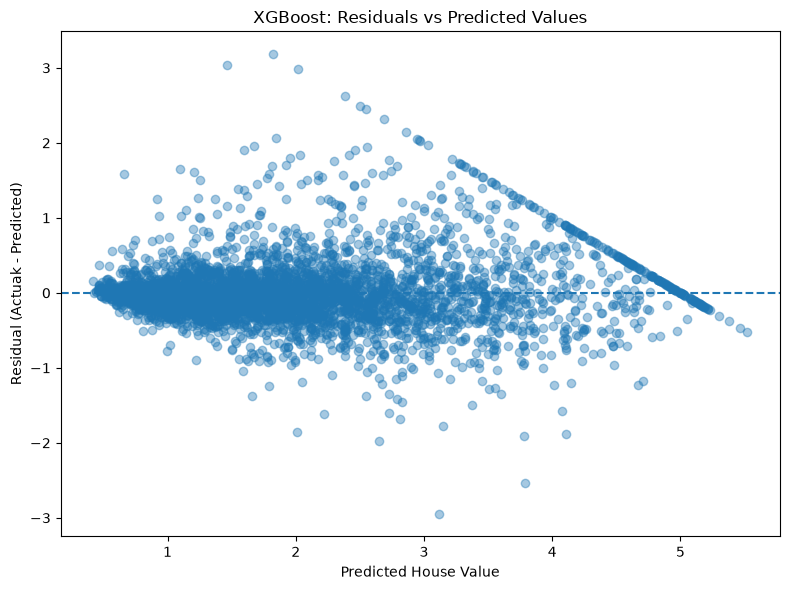

In [27]:
residuals = y_test - y_pred_xgb

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_xgb,
    residuals,
    alpha=0.4
)

plt.axhline(
    y = 0,
    linestyle = "--"
)

plt.xlabel("Predicted House Value")
plt.ylabel("Residual (Actuak - Predicted)")
plt.title("XGBoost: Residuals vs Predicted Values")

plt.tight_layout()
plt.show()

### Residual Analysis

We plotted residuals against predicted house values to investigate systematic patterns in the model's errors.

Most residuals are distributed around zero, indicating that the model does not exhibit an obvious large directional error across the entire prediction range.

However, the spread of residuals increases at higher predicted values. This suggests that prediction errors become more variable for higher-value properties, a pattern consistent with heteroscedasticity.

A distinctive diagonal band appears in the upper-right region of the plot. This is largely explained by the dataset's upper target cap. For observations with an actual target near 5.00001, the residual is approximately equal to 5.00001 minus the predicted value, producing a descending linear pattern.

The plot also contains several substantial outliers, confirming that some individual predictions remain inaccurate despite strong overall evaluation metrics.

This analysis highlights the importance of examining residuals alongside aggregate metrics when evaluating a regression model.

In [28]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Tuned Decision Tree",
        "Random Forest",
        "Tuned Random Forest",
        "Gradient Boosting",
        "Tuned XGBoost"
    ],
    "Test MAE": [
        0.5332,
        0.4542,
        0.4014,
        0.3277,
        0.3279,
        0.3014,
        0.2833
    ],
    "Test RMSE": [
        0.7456,
        0.7030,
        0.5966,
        0.5060,
        0.4946,
        0.4549,
        0.4342
    ],
    "Test R²": [
        0.5758,
        0.6228,
        0.7283,
        0.8046,
        0.8133,
        0.8421,
        0.8561
    ]
})

comparison

,Model,Test MAE,Test RMSE,Test R²
0,Linear Regression,0.5332,0.7456,0.5758
1,Decision Tree,0.4542,0.7030,0.6228
2,Tuned Decision Tree,0.4014,0.5966,0.7283
3,Random Forest,0.3277,0.5060,0.8046
4,Tuned Random Forest,0.3279,0.4946,0.8133
5,Gradient Boosting,0.3014,0.4549,0.8421
6,Tuned XGBoost,0.2833,0.4342,0.8561


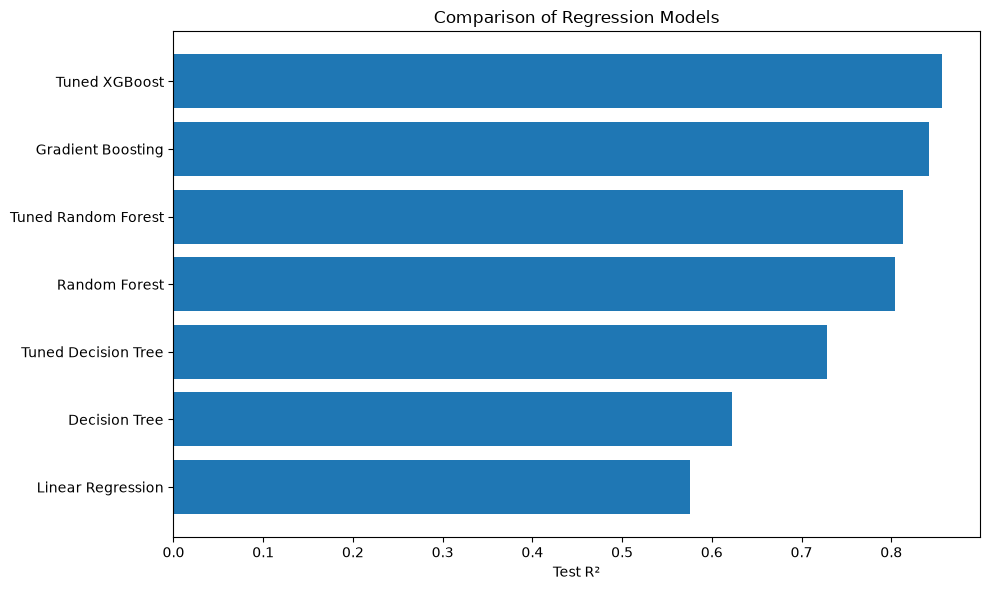

In [29]:
plt.figure(figsize=(10, 6))

plt.barh(
    comparison["Model"],
    comparison["Test R²"]
)
plt.xlabel("Test R²")
plt.title("Comparison of Regression Models")

plt.gca().invert_yaxis
plt.tight_layout()
plt.show()

## Final Conclusion

In this notebook, we studied XGBoost Regression and applied it to the California Housing dataset.

We explored the intuition behind gradient-boosted trees, investigated important hyperparameters, and used GridSearchCV with five-fold cross-validation to select a promising configuration.

We also examined feature importance, prediction errors, actual-versus-predicted values, and residual patterns.

Our tuned XGBoost model achieved the following results on the held-out test set:

- **MAE:** 0.2833, approximately $28,330
- **RMSE:** 0.4342, approximately $43,424
- **R²:** 0.8561

Among the seven models evaluated in this project, tuned XGBoost achieved the strongest test performance.

The feature-importance analysis identified median income as the dominant predictor, with geographic features also contributing substantially. Error analysis revealed that the model struggles with certain unusual observations, particularly those affected by the dataset's upper target cap.

This project demonstrated the progression from a simple linear baseline to more sophisticated tree-based ensemble models. It also highlighted the importance of cross-validation, appropriate evaluation metrics, hyperparameter tuning, and investigating individual prediction errors.

Although the final model explains a substantial proportion of the variation in the held-out target values, it is not perfect. Its predictions remain limited by the information available in the dataset and the target's upper cap.

The model should therefore be interpreted as a predictive model for this dataset, not as a complete or universally reliable house-valuation system.

In [30]:
from pathlib import Path
import joblib

# Project root: parent of the notebook directory
PROJECT_ROOT = Path.cwd().parent

# Create the models directory if it does not exist
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Select the best estimator from GridSearch
best_xgb = grid_search_xbr.best_estimator_

# Save the trained model
model_path = MODEL_DIR / "xgboost_housing_model.joblib"

joblib.dump(best_xgb, model_path)

print(f"Model saved to: {model_path}")

Model saved to: c:\Projects\Housing-Price-Prediction\models\xgboost_housing_model.joblib


In [31]:
assert model_path.exists(), "Model file was not created."

print(f"Model file size: {model_path.stat().st_size / 1024:.2f} KB")

Model file size: 3400.88 KB
